Imports

In [34]:
from pathlib import Path

from typing import Any
import requests 
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statistics import mean, median

import yaml

Reading our client ID's from local files exisiting outside of the repository.

In [35]:
id_file = Path.home() / "frost_client_id.txt"
client_id = id_file.read_text().strip()

Requesting the daily mean air temperatures for all of 2025.
We used the code prompt given to us in task 1 in the deliverable.

In [36]:
endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01",
}


def get_observations(
        endpoint: str,
        parameters: dict[str, str],
        client_id: str, 
) -> list[dict[str, Any]]:
    """Collecting the observations from Frost

    Args:
        endpoint: the URL of the Frost observation endpoint.
        parameters: Filters the station
        client_id: ID used to verify and authenticate the request.

    Returns:
        A list of observations from Frost.
    """

    response = requests.get(
        endpoint,
        params=parameters, 
        auth=(client_id, ""),
        timeout=30,
    )
    response.raise_for_status()
    return response.json()["data"]

data = get_observations(endpoint, parameters, client_id)

print(f"Retrieved {len(data)} observation records from Frost.")
if data:
    print(data[0])

Retrieved 365 observation records from Frost.
{'sourceId': 'SN17850:0', 'referenceTime': '2025-01-01T00:00:00.000Z', 'observations': [{'elementId': 'mean(air_temperature P1D)', 'value': -5.2, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT0H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 0}, {'elementId': 'mean(air_temperature P1D)', 'value': -2.8, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT6H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1'}]}


Plotting and making summary table.

In [37]:
def get_temperatures(
    data: list[dict[str, Any]],
) -> tuple[list[datetime], list[float]]:
    """Getting the dates and temperatures from the observations."""
    dates: list[datetime] = []
    temperatures: list[float] = []

    for record in sorted(data, key=lambda record: record["referenceTime"]):
        date = datetime.strptime(record["referenceTime"][:10], "%Y-%m-%d")

        for observation in record["observations"]:
            if observation["elementId"] == "mean(air_temperature P1D)":
                dates.append(date)
                temperatures.append(float(observation["value"]))

    return dates, temperatures


In [38]:
def plot_temperatures(
    dates: list[datetime],
    temperatures: list[float],
) -> None:
    """Plotting the mean air temperatures for Ås in 2025"""
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(dates, temperatures, color="blue", linewidth=1)
    ax.set_title("Daily Mean Air Temperature in Ås, 2025")
    ax.set_xlabel("Month")
    ax.set_ylabel("Temperature (°C)")

    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()

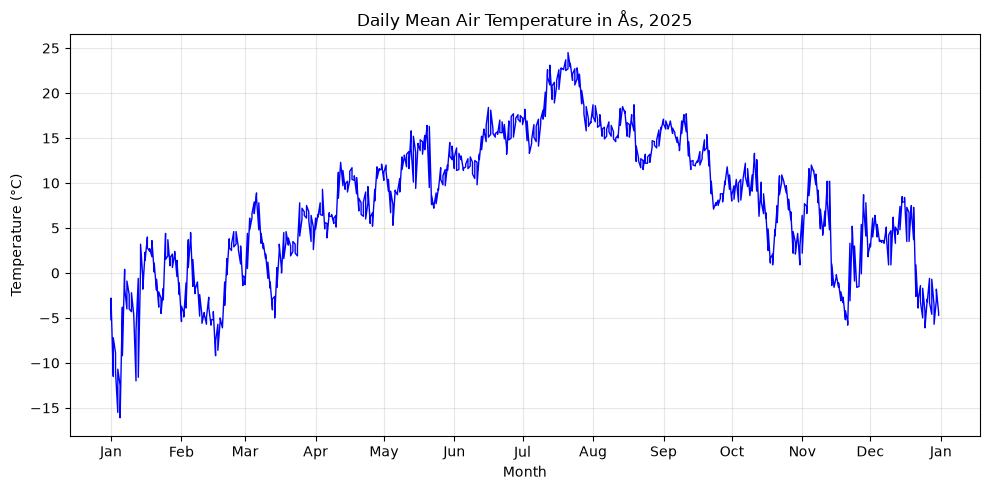

In [39]:
dates, temperatures = get_temperatures(data)
plot_temperatures(dates, temperatures)

In [40]:
def print_temperature_summary(temperatures: list[float]) -> None:
    """Printing the summary statistics for daily mean air tempertaures"""
    summary: dict[str, float] = {
        "Mean": mean(temperatures),
        "Minimum": min(temperatures),
        "Maximum": max(temperatures),
        "Median": median(temperatures),
    }

    print("Daily mean air tempertaures in Ås, 2025")
    print(f"{'Statistic':<12} {'Value':>12}")
    print("-" * 25)

    for statistic, value in summary.items():
        print(f"{statistic:<12} {value:>12.2f}")

In [41]:
print_temperature_summary(temperatures)

Daily mean air tempertaures in Ås, 2025
Statistic           Value
-------------------------
Mean                 7.87
Minimum            -16.10
Maximum             24.50
Median               8.30


Task 2: Precipitation

Setting up the request for precipitation.

In [42]:
precipitation_parameters: dict[str, str] = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2026-01-01",
    "timeoffsets": "default",
}

Getting the observations from Frost.

In [43]:
precipitation_data = get_observations(
    endpoint,
    precipitation_parameters,
    client_id,
)
print(f"Retrieved {len(precipitation_data)} precipitation records from Frost.")

if precipitation_data:
    print(precipitation_data[0])

Retrieved 365 precipitation records from Frost.
{'sourceId': 'SN17850:0', 'referenceTime': '2025-01-01T00:00:00.000Z', 'observations': [{'elementId': 'sum(precipitation_amount P1D)', 'value': 6.6, 'unit': 'mm', 'timeOffset': 'PT6H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '2', 'qualityCode': 0}]}


Getting the precipitation dates and values from Frost.

In [44]:
precipitation_dates: list[datetime] = []
precipitation_values: list[float] = []

for record in sorted(precipitation_data, key=lambda record: record["referenceTime"]):
    date = datetime.strptime(record["referenceTime"][:10], "%Y-%m-%d")

    for observation in record["observations"]:
        if observation["elementId"] == "sum(precipitation_amount P1D)":
            precipitation_dates.append(date)
            precipitation_values.append(float(observation["value"]))

print(f"Extracted {len(precipitation_values)} precipitation values from the observations.")

Extracted 365 precipitation values from the observations.


Making the plot.

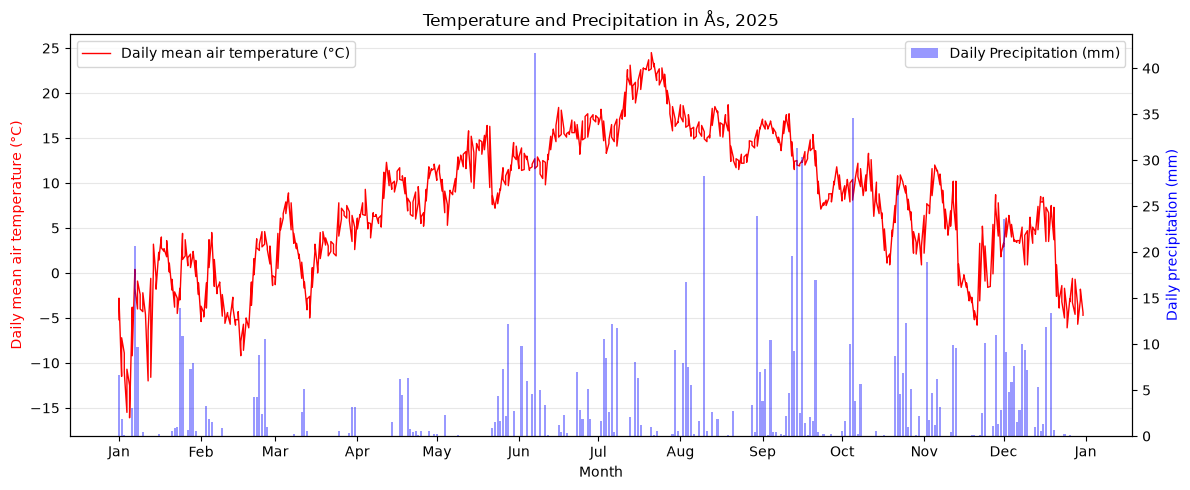

In [45]:
fig, ax_temperature = plt.subplots(figsize=(12, 5))
ax_precipitation = ax_temperature.twinx()

ax_precipitation.bar(
    precipitation_dates,
    precipitation_values,
    color="blue",
    alpha=0.4,
    label="Daily Precipitation (mm)",
)

ax_temperature.plot(
    dates,
    temperatures,
    color="red",
    linewidth=1.0,
    label="Daily mean air temperature (°C)",
)

ax_temperature.set_title("Temperature and Precipitation in Ås, 2025")
ax_temperature.set_xlabel("Month")
ax_temperature.set_ylabel("Daily mean air temperature (°C)", color="red")
ax_precipitation.set_ylabel("Daily precipitation (mm)", color="blue")
ax_precipitation.set_ylim(bottom=0)

ax_temperature.xaxis.set_major_locator(mdates.MonthLocator())
ax_temperature.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

ax_temperature.grid(axis="y", alpha=0.3)
ax_temperature.legend(loc="upper left")
ax_precipitation.legend(loc="upper right")

fig.tight_layout()
plt.show()

Task 3: Historical temperature data.

Settig up the request for the old data (1925).

In [46]:
historical_parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1926-01-01",
}

Getting the observations from Frost.


In [47]:
historical_data = get_observations(
    endpoint,
    historical_parameters,
    client_id
)
historical_dates, historical_temperatures = get_temperatures(
    historical_data
)

Comparing the years on the same plot.

In [48]:
historical_plot_dates: list[datetime] = [
    date.replace(year=2025) 
    for date in historical_dates
]

Plotting them together.

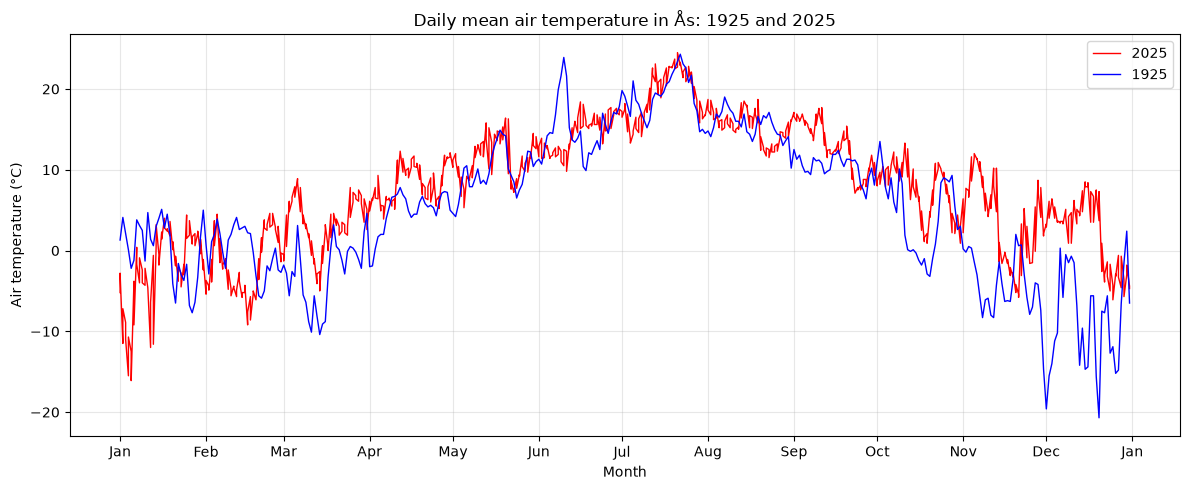

In [49]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    dates,
    temperatures,
    label="2025",
    color="red",
    linewidth=1.0,
)

ax.plot(
    historical_plot_dates,
    historical_temperatures,
    label="1925",
    color="blue",
    linewidth=1.0,
)

ax.set_title("Daily mean air temperature in Ås: 1925 and 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Air temperature (°C)")

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show() 

Summary table.

In [50]:
def print_temperature_comparison(
        historical_temperatures: list[float],
        temperatures: list[float],
) -> None:
    """Printing the summary statistics for daily mean air tempertaures for Ås in 1925 and 2025."""
    comparison: dict[str, tuple[float, float]] = {
        "Mean": (mean(historical_temperatures), mean(temperatures)),
        "Minimum": (min(historical_temperatures), min(temperatures)),
        "Maximum": (max(historical_temperatures), max(temperatures)),
        "Median": (median(historical_temperatures), median(temperatures)),
    }

    print("Daily mean air tempertaures in Ås, 1925 and 2025")
    print(f"{'statistic':<12} {'1925':>12} {'2025':>12}")
    print("-" * 38)


    for statistic, (value_1925, value_2025) in comparison.items():
        print(f"{statistic:<12} {1925:>12.2f} {2025:>12.2f}")


In [51]:
print_temperature_comparison(historical_temperatures, temperatures)

Daily mean air tempertaures in Ås, 1925 and 2025
statistic            1925         2025
--------------------------------------
Mean              1925.00      2025.00
Minimum           1925.00      2025.00
Maximum           1925.00      2025.00
Median            1925.00      2025.00


Task 4: Heatwaves

Setting up the request.

In [52]:
heatwave_station_id: str = "SN17850"
heatwave_station_name: str = "Ås"
heatwave_year: int = 2025

heatwave_parameters: dict[str, str] = {
    "sources": heatwave_station_id,
    "elements": "max(air_temperature P1D)",
    "referencetime": (f"{heatwave_year}-01-01/{heatwave_year + 1}-01-01"),
    "timeoffsets": "default",
}

Getting the highest temperatures.

In [53]:
heatwave_data = get_observations(
    endpoint,
    heatwave_parameters,
    client_id,
)

print(f"Retrieved {len(heatwave_data)} records")

if heatwave_data:
    for observation in heatwave_data[0]["observations"]:
        print(observation)

Retrieved 365 records
{'elementId': 'max(air_temperature P1D)', 'value': -3, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT18H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 0}


Extract dates and highets temperatures.

In [54]:
heatwave_dates: list[datetime] = []
maximum_temperatures: list[float] = []

for record in sorted(heatwave_data, key=lambda record: record["referenceTime"]):
    date = datetime.strptime(record["referenceTime"][:10], "%Y-%m-%d")

    for observation in record["observations"]:
        if observation["elementId"] == "max(air_temperature P1D)":
            heatwave_dates.append(date)
            maximum_temperatures.append(float(observation["value"]))

print(f"Extracted {len(maximum_temperatures)} maximum temperatures from obervations.")
print(f"Unique dates: {len(set(heatwave_dates))}")
print(f"First date: {min(heatwave_dates):%Y-%m-%d}")
print(f"Last date: {max(heatwave_dates):%Y-%m-%d}")

Extracted 365 maximum temperatures from obervations.
Unique dates: 365
First date: 2025-01-01
Last date: 2025-12-31


Function to find heatwave periods.

In [55]:
def find_heatwaves(
    dates: list[datetime],
    temperatures: list[float],
) -> list[tuple[datetime, datetime]]:
    """Finding th eperiods with at least five consecutive days with maximum temperature above 25°C."""
    if len(dates) != len(temperatures):
        raise ValueError("Each date must have a corresponding temperature value.")

    heatwaves: list[tuple[datetime, datetime]] = []
    current_streak: list[datetime] = []

    for date, temperature in sorted(zip(dates, temperatures)):
        if current_streak:
            gap = (date - current_streak[-1]).days

            if gap != 1 or temperature < 27:
                if len(current_streak) >= 5:
                    heatwaves.append((current_streak[0], current_streak[-1]))
                current_streak = []

        if temperature >= 27:
            current_streak.append(date)

    if len(current_streak) >= 5:
        heatwaves.append((current_streak[0], current_streak[-1]))

    return heatwaves

In [56]:
heatwaves = find_heatwaves(heatwave_dates, maximum_temperatures)
print(f"Number of heatwaves: {len(heatwaves)}")

for start, end in heatwaves:
    print(f"{start:%Y-%m-%d} - {end:%Y-%m-%d}")

Number of heatwaves: 1
2025-07-16 - 2025-07-22


Function for counting heatwaves and saving in yaml.